## Circular Task Analysis

#Background

This project analyzes data from the circular task described in Fauviaux et al. (2021). Participants move the mouse along a ring as fast and as accurately as possible. The data were recorded with the MouseReMoCo software.

The session consists of 5 recordings of 20 s, separated by 20 s pauses.



# Code to help us

In [ ]:
# imports (this is all you need for this assignment - please, do not import anything else)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle , Circle
import os

# very useful for plots that yo can zoom in-out
%matplotlib widget

# import pandas as pd # we do not use pandas here
# if the present working directory is the directory of this file, change the path to the project root
if os.getcwd().endswith("notebooks"):
    os.chdir("..")

## Header Information

In [6]:
DATA_FILE = "data/001MoDe_R1.csv"

# Read the header line (first line: "key value;key value;...")
with open(DATA_FILE, "r", encoding="utf-8") as f:
    first_line = f.readline().strip()

header = {}
for item in first_line.split(";"):
    key, _, value = item.partition(" ")
    try:
        header[key] = float(value)
    except ValueError:
        header[key] = value

# Display the header information
print(f"Header line information in '{DATA_FILE}':")
for key, value in header.items():
    print(f"  {key}: {value}")

Header line information in 'data/001MoDe_R1.csv':
  screenWidth: 1104.0
  screenHeight: 661.0
  cornerX: 302.0
  cornerY: 80.0
  centerX: 552.0
  centerY: 330.0
  externalRadius: 250.0
  internalRadius: 170.0
  borderRadius: 1.0
  cursorRadius: 16.0
  indexOfDifficulty: 28.00696429476858
  taskRadius: 209.5
  taskTolerance: 47.0
  borderColor: java.awt.Color[r=255,g=255,b=255]
  backgroundColor: java.awt.Color[r=0,g=0,b=0]
  cursorColorRecord: java.awt.Color[r=255,g=0,b=0]
  cursorColorWait: java.awt.Color[r=255,g=255,b=0]
  autoStart: 3600.0
  cycleMaxNumber: 6.0
  cycleDuration: 20.0
  software: LSL-mouse
  version: 1.2.0rc5
  task: CircularTarget
  isWithLSL: false


## Markers Information

In [7]:
MARKER_FILE = "data/001MoDe_R1.marker.csv"

# Read the markers: each line is "date,timestamp,event"
markers = []
with open(MARKER_FILE, "r", encoding="utf-8") as f:
    for line in f:
        parts = line.strip().split(",", 2)
        if len(parts) == 3 and parts[1].isdigit():
            markers.append((int(parts[1]), parts[2]))

# Display the markers
print(f"Markers in '{MARKER_FILE}':")
for timestamp, event in markers:
    print(f"{timestamp}: {event}")

Markers in 'data/001MoDe_R1.marker.csv':
1616776712325: KeyTyped=32 DoCycleChange
1616776712331: DoCycleChange:DoStartCycleTimedSequence
1616776712333: DoCycleChange:DoRecord RecordDone=0 PauseDone=0 ToDo=6
1616776732336: DoCycleChange:DoPause RecordDone=1 PauseDone=0 ToDo=6
1616776752340: DoCycleChange:DoRecord RecordDone=1 PauseDone=1 ToDo=6
1616776772351: DoCycleChange:DoPause RecordDone=2 PauseDone=1 ToDo=6
1616776792372: DoCycleChange:DoRecord RecordDone=2 PauseDone=2 ToDo=6
1616776812386: DoCycleChange:DoPause RecordDone=3 PauseDone=2 ToDo=6
1616776832390: DoCycleChange:DoRecord RecordDone=3 PauseDone=3 ToDo=6
1616776852404: DoCycleChange:DoPause RecordDone=4 PauseDone=3 ToDo=6
1616776872419: DoCycleChange:DoRecord RecordDone=4 PauseDone=4 ToDo=6
1616776892433: DoCycleChange:DoPause RecordDone=5 PauseDone=4 ToDo=6
1616776898364: KeyTyped=113 WINDOW_CLOSING
1616776898367: 


## Software Summary Table

At the end of `001MoDe_R1.marker.csv`, MouseReMoCo writes a summary table with the statistics it computed for each record (`nLaps`, `Re`, `Te`, `error`, `MT/lap`, `IDe/lap`, `Be`, `IPe`). The first row ("Theory") gives the values expected from the task parameters. We will later recompute these values from the raw data and compare them with this table.

In [10]:
MARKER_FILE = "data/001MoDe_R1.marker.csv"

# Print the summary table computed by the software (end of the marker file)
print(f"Software summary table in '{MARKER_FILE}':")
with open(MARKER_FILE, "r", encoding="utf-8") as f:
    table_started = False
    for line in f:
        line = line.strip()
        if "Var" in line and "nLaps" in line:   # start of the table
            table_started = True
        if table_started:
            print(line)

Software summary table in 'data/001MoDe_R1.marker.csv':
Var , nLaps ,      Re ,      Te ,   error ,  MT/lap , IDe/lap ,      Be ,     IPe ,
unit ,   lap ,   pixel ,   pixel ,       % ,   s/lap , bit/lap ,  double ,   bit/s ,
Theory ,  1.00 ,  209.50 ,   47.00 ,    3.88 ,         ,         ,    1.00 ,         ,
Rec001 ,-10.85 ,  213.87 ,   91.79 ,    3.90 ,    1.84 ,   14.64 ,    1.95 ,    7.94 ,
Rec002 ,-11.97 ,  209.85 ,   34.46 ,    0.74 ,    1.59 ,   38.27 ,    0.73 ,   24.04 ,
Rec003 ,-13.26 ,  209.43 ,   42.42 ,    2.81 ,    1.45 ,   31.02 ,    0.90 ,   21.40 ,
Rec004 ,-12.83 ,  209.46 ,   37.14 ,    0.13 ,    1.49 ,   35.43 ,    0.79 ,   23.72 ,
Rec005 ,-14.74 ,  210.89 ,   43.88 ,    2.84 ,    1.30 ,   30.20 ,    0.93 ,   23.20 ,
Rec006 ,  0.00 ,    0.00 ,    0.00 ,     NaN ,     NaN ,     NaN ,    0.00 ,    0.00 ,


## Record Times

Each record starts with a `DoRecord` marker and ends with the next marker (`DoPause`). Pairing them gives the start and end of each record, in milliseconds since the Unix epoch, together with its duration. These intervals are used later to split the mouse data into records and exclude the pauses.

In [11]:
MARKER_FILE = "data/001MoDe_R1.marker.csv"

# Read the events: each line is "date,timestamp,event"
events = []
with open(MARKER_FILE, "r", encoding="utf-8") as f:
    for line in f:
        parts = line.strip().split(",", 2)
        if len(parts) == 3 and parts[1].isdigit():
            events.append((int(parts[1]), parts[2]))

# Pair each DoRecord with the next event (DoPause) to get the record intervals
print("record times (milliseconds since the Unix epoch, 00:00:00 UTC on January 1, 1970):")
for i, (start, event) in enumerate(events):
    if "DoRecord" in event and i + 1 < len(events):
        end = events[i + 1][0]
        print(f"{start} to {end} ({(end - start) / 1000:.3f} s)")

record times (milliseconds since the Unix epoch, 00:00:00 UTC on January 1, 1970):
1616776712333 to 1616776732336 (20.003 s)
1616776752340 to 1616776772351 (20.011 s)
1616776792372 to 1616776812386 (20.014 s)
1616776832390 to 1616776852404 (20.014 s)
1616776872419 to 1616776892433 (20.014 s)


## Record Times (Relative)

The same record intervals are now expressed in seconds, relative to the first sample of the data file (time zero). This is the time axis used in the figures. The first record starts a few milliseconds after time zero, because the first mouse sample was recorded just before the first `DoRecord` marker.

In [12]:
DATA_FILE = "data/001MoDe_R1.csv"
MARKER_FILE = "data/001MoDe_R1.marker.csv"

# Read the events: each line is "date,timestamp,event"
events = []
with open(MARKER_FILE, "r", encoding="utf-8") as f:
    for line in f:
        parts = line.strip().split(",", 2)
        if len(parts) == 3 and parts[1].isdigit():
            events.append((int(parts[1]), parts[2]))

# Time zero = timestamp of the first data sample (line 5 of the data file)
with open(DATA_FILE, "r", encoding="utf-8") as f:
    lines = f.readlines()
t0 = int(lines[4].split(",")[0])

# Pair each DoRecord with the next event (DoPause), in seconds since t0
print("record times (seconds since the first DoRecord marker):")
for i, (start, event) in enumerate(events):
    if "DoRecord" in event and i + 1 < len(events):
        end = events[i + 1][0]
        print(f"{(start - t0) / 1000:7.3f} to {(end - t0) / 1000:7.3f} ({(end - start) / 1000:.3f} s)")

record times (seconds since the first DoRecord marker):
  0.004 to  20.007 (20.003 s)
 40.011 to  60.022 (20.011 s)
 80.043 to 100.057 (20.014 s)
120.061 to 140.075 (20.014 s)
160.090 to 180.104 (20.014 s)


## Raw Time Series

Mouse positions (x and y) are plotted as a function of time. Rows with `timestamp = 0` (separators between records) are removed, positions are centered on the task center (`centerX = 552`, `centerY = 330`), and only samples recorded between a `DoRecord` and the next `DoPause` marker are kept. Dashed vertical lines show the start (black) and end (red) of each record; the gaps in between are the pauses.

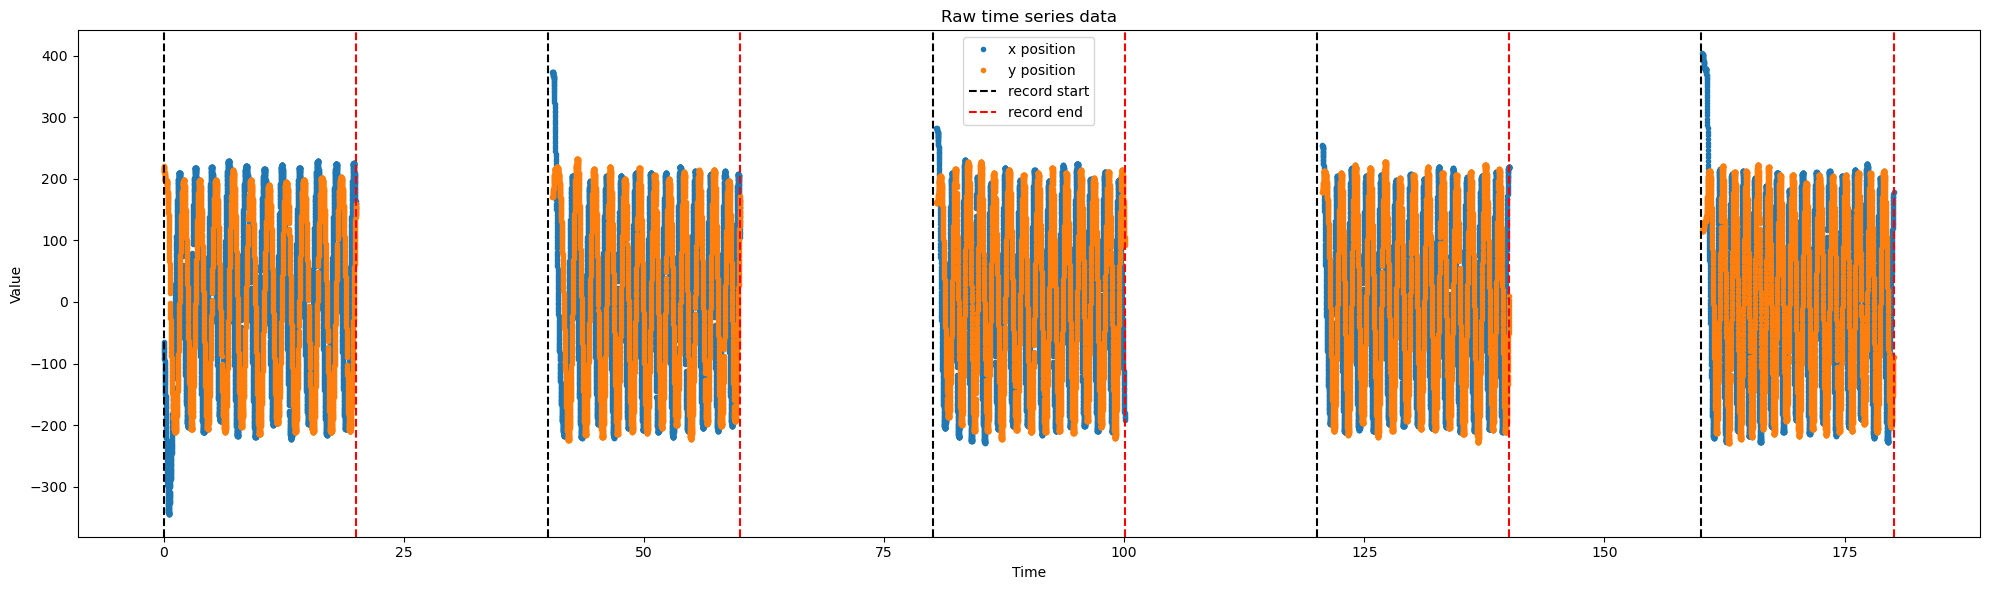

In [26]:


DATA_FILE = "data/001MoDe_R1.csv"
MARKER_FILE = "data/001MoDe_R1.marker.csv"
CENTER_X, CENTER_Y = 552, 330

# Load the raw data and remove the separator rows (timestamp = 0)
data = np.loadtxt(DATA_FILE, delimiter=",", skiprows=4)
data = data[data[:, 0] > 0]
timestamps, mouse_x, mouse_y = data[:, 0], data[:, 1], data[:, 2]

# Center the positions on the target
x_centered = mouse_x - CENTER_X
y_centered = mouse_y - CENTER_Y

# Read the events: each line is "date,timestamp,event"
events = []
with open(MARKER_FILE, "r", encoding="utf-8") as f:
    for line in f:
        parts = line.strip().split(",", 2)
        if len(parts) == 3 and parts[1].isdigit():
            events.append((int(parts[1]), parts[2]))

# Record intervals: each DoRecord ends at the next event (DoPause)
intervals = [(events[i][0], events[i + 1][0])
             for i in range(len(events) - 1) if "DoRecord" in events[i][1]]

# Keep only the samples inside the records, time in seconds since the first sample
t0 = timestamps[0]
in_record = np.zeros(len(timestamps), dtype=bool)
for start, end in intervals:
    in_record |= (timestamps >= start) & (timestamps <= end)
t = (timestamps[in_record] - t0) / 1000
x = x_centered[in_record]
y = y_centered[in_record]

# Plot
plt.figure(figsize=(20, 6))
plt.plot(t, x, ".", color="tab:blue", label="x position")
plt.plot(t, y, ".", color="tab:orange", label="y position")
for i, (start, end) in enumerate(intervals):
    plt.axvline((start - t0) / 1000, color="black", linestyle="--", label="record start" if i == 0 else None)
    plt.axvline((end - t0) / 1000, color="red", linestyle="--", label="record end" if i == 0 else None)
plt.title("Raw time series data")
plt.xlabel("Time")
plt.ylabel("Value")
plt.legend()
plt.tight_layout()
plt.show()

## Raw Trajectory

The trajectory of the cursor is plotted in the (x, y) plane, centered on the task center. Each record is drawn separately so that no line connects the end of one record to the start of the next. Green dots mark the samples where the cursor was inside the target (`mouseInTarget = 1`), and the red circles show the target ring (task radius 209.5 px ± half the tolerance of 47 px, i.e. radii 186 and 233 px). The blue tails outside the ring correspond to the start of each record, when the cursor moves from its previous position to the ring.

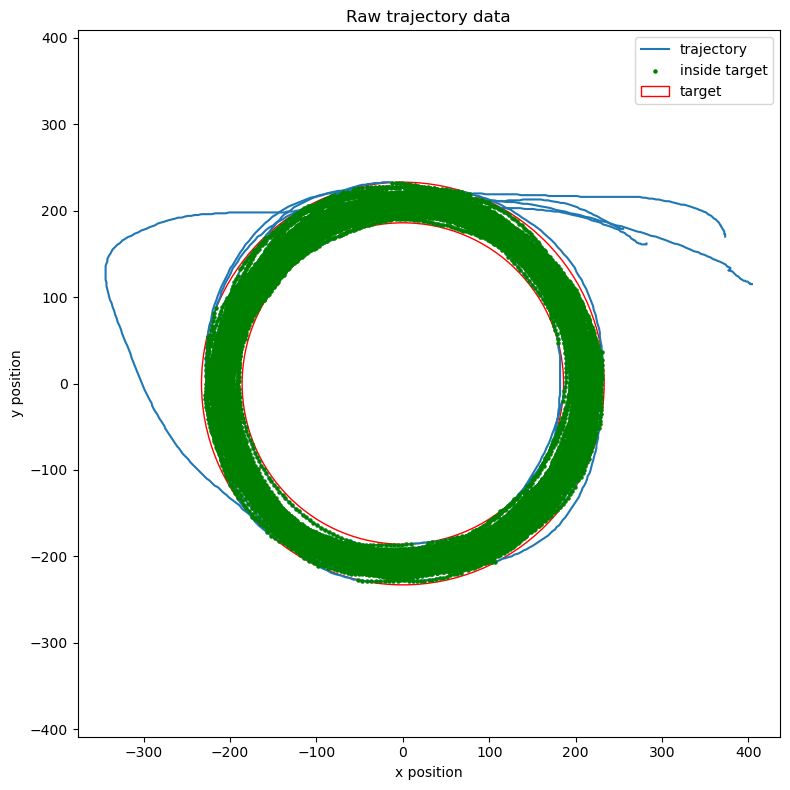

In [ ]:

DATA_FILE = "data/001MoDe_R1.csv"
MARKER_FILE = "data/001MoDe_R1.marker.csv"
CENTER_X, CENTER_Y = 552, 330
TASK_RADIUS, TASK_TOLERANCE = 209.5, 47

# Load the raw data and remove the separator rows (timestamp = 0)
data = np.loadtxt(DATA_FILE, delimiter=",", skiprows=4)
data = data[data[:, 0] > 0]
timestamps = data[:, 0]
x = data[:, 1] - CENTER_X          # positions centered on the target
y = data[:, 2] - CENTER_Y
in_target = data[:, 3] == 1

# Read the events: each line is "date,timestamp,event"
events = []
with open(MARKER_FILE, "r", encoding="utf-8") as f:
    for line in f:
        parts = line.strip().split(",", 2)
        if len(parts) == 3 and parts[1].isdigit():
            events.append((int(parts[1]), parts[2]))

# Record intervals: each DoRecord ends at the next event (DoPause)
intervals = [(events[i][0], events[i + 1][0])
             for i in range(len(events) - 1) if "DoRecord" in events[i][1]]

# Plot the trajectory record by record (no line between two records)
fig, ax = plt.subplots(figsize=(8, 8))
in_record = np.zeros(len(timestamps), dtype=bool)
for i, (start, end) in enumerate(intervals):
    mask = (timestamps >= start) & (timestamps <= end)
    in_record |= mask
    ax.plot(x[mask], y[mask], color="tab:blue", label="trajectory" if i == 0 else None)

# Samples inside the target (only during records)
inside = in_record & in_target
ax.scatter(x[inside], y[inside], s=5, color="green", label="inside target", zorder=3)

# Target ring: radii 209.5 -/+ 47/2 = 186 and 233
ax.add_patch(Circle((0, 0), TASK_RADIUS - TASK_TOLERANCE / 2, fill=False, edgecolor="red", label="target"))
ax.add_patch(Circle((0, 0), TASK_RADIUS + TASK_TOLERANCE / 2, fill=False, edgecolor="red"))

ax.set_aspect("equal", adjustable="datalim")
ax.set_title("Raw trajectory data")
ax.set_xlabel("x position")
ax.set_ylabel("y position")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()